# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name: Shabab Zahra**

**Student ID: 023-24-0088**

**Section: D**

**GitHub: https://github.com/shababzahraa/Machine-Learning-Tasks**

**Kaggle:**
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [38]:
# Task 1 — load spam.csv, inspect shape/head/class balance
df_spam = pd.read_csv('spam.csv', encoding='latin-1')
print("Number of Rows and Columns : ",df_spam.shape)
df_spam = df_spam.rename(columns={'v1' : 'Label', 'v2' : 'Message'})
print("Class Balance")
print(df_spam['Label'].value_counts())
print(df_spam['Label'].value_counts(normalize=True)*100)
print(df_spam.columns)
df_spam = df_spam.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'])
print("Number of Rows and Columns : ",df_spam.shape)

Number of Rows and Columns :  (5572, 5)
Class Balance
Label
ham     4825
spam     747
Name: count, dtype: int64
Label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64
Index(['Label', 'Message', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')
Number of Rows and Columns :  (5572, 2)


In [39]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
df_tweets = pd.read_csv('Tweets.csv')
print("Number of Rows and Columns : ",df_tweets.shape)
print("Class Balance")
print(df_tweets['airline_sentiment'].value_counts())
print(df_tweets['airline_sentiment'].value_counts(normalize=True)*100)
df_tweets = df_tweets.drop(df_tweets[df_tweets['airline_sentiment'] == 'neutral'].index)
print("Number of Rows and Columns : ",df_tweets.shape)
print("Class Balance After Removing Neutral")
print(df_tweets['airline_sentiment'].value_counts())
print(df_tweets['airline_sentiment'].value_counts(normalize=True)*100)


Number of Rows and Columns :  (14640, 15)
Class Balance
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64
airline_sentiment
negative    62.691257
neutral     21.168033
positive    16.140710
Name: proportion, dtype: float64
Number of Rows and Columns :  (11541, 15)
Class Balance After Removing Neutral
airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64
airline_sentiment
negative    79.525171
positive    20.474829
Name: proportion, dtype: float64


**Answer 2 (Task A — spam):**
_The SMS Spam Detection model identifies unwanted or fraudulent SMS messages so they can be filtered into a spam folder, while legitimate messages remain in the inbox. It is a binary classification problem because each message is classified into one of two categories: spam or ham._

**Answer 2 (Task B — sentiment):**
_The Sentiment Analysis model identifies whether customers have positive or negative opinions about airlines, helping airlines understand customer satisfaction and respond to complaints. It is a binary classification problem because neutral tweets have been removed, leaving only two possible classes: positive and negative._

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [40]:
# Task 3 — clean text
df_spam['Message'] = df_spam['Message'].str.lower()
print(df_spam['Message'].head())


0    go until jurong point, crazy.. available only ...
1                        ok lar... joking wif u oni...
2    free entry in 2 a wkly comp to win fa cup fina...
3    u dun say so early hor... u c already then say...
4    nah i don't think he goes to usf, he lives aro...
Name: Message, dtype: object


In [42]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

df_spam['Label'] = df_spam['Label'].map({'ham' : 0, 'spam' : 1})

X = df_spam['Message']
y = df_spam['Label']

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

vectorizer = CountVectorizer()
x_train_vectorized = vectorizer.fit_transform(x_train)
x_test_vectorized = vectorizer.transform(x_test)

print("Vocabulary size = ", len(vectorizer.get_feature_names_out()))

print("Training shape:", x_train_vectorized.shape)
print("Testing shape:", x_test_vectorized.shape)

Vocabulary size =  7701
Training shape: (4457, 7701)
Testing shape: (1115, 7701)


**Answer 4 (why fit on training data only):**
_The vectorizer must learn its vocabulary from the training messages only, so the test data remains completely unseen during training. Fitting on the full dataset would allow information from the test set to influence the features, causing data leakage and potentially giving an overly optimistic evaluation._

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy :  0.9839
Precision :  0.9645
Recall :  0.9128
F1 Score :  0.9379


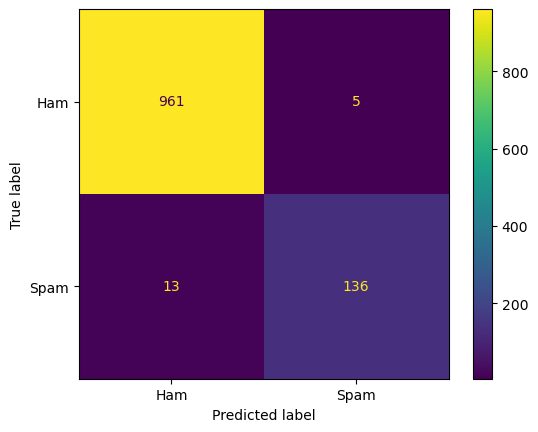

In [45]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib as pyplot

nb_model = MultinomialNB()

nb_model.fit(x_train_vectorized, y_train)

y_pred = nb_model.predict(x_test_vectorized)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy : ", round(accuracy,4))
print("Precision : ", round(precision,4))
print("Recall : ", round(recall,4))
print("F1 Score : ", round(f1,4))

confusion = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=['Ham', 'Spam'])
display.plot()
plt.show()

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9839 |
| Precision | 0.9645 |
| Recall | 0.9128 |
| F1-score | 0.9379 |

**Answer 6:**
6.	A false positive here means a real (ham) message gets wrongly flagged as spam and possibly hidden from the user; a false negative means a spam message gets through to their inbox. In 3–4 sentences, argue which kind of error is worse for this specific application, and therefore which metric (precision or recall) you would prioritize if you had to tune the model further.

_A false positive is more harmful in this application because a legitimate message may be hidden from the user, causing them to miss important information. A false negative is less harmful because the spam message reaches the inbox, where the user can still identify and delete it. Therefore, I would prioritize precision when tuning the model to reduce the number of legitimate messages incorrectly classified as spam. However, recall should also remain reasonably high to ensure that most spam messages are detected._

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [46]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
log_probabilites = nb_model.feature_log_prob_

words = vectorizer.get_feature_names_out()

spam_scores = log_probabilites[1] - log_probabilites[0]

spam_indices = np.argsort(spam_scores)[-15:][::-1]
ham_indices = np.argsort(spam_scores)[:15]

print("Words associated with spam: ", words[spam_indices])
print("Words associated with ham: ", words[ham_indices])


Words associated with spam:  ['claim' 'prize' '150p' 'tone' '18' 'cs' '500' 'guaranteed' '1000' 'uk'
 '150ppm' 'awarded' 'www' 'collection' 'ringtone']
Words associated with ham:  ['gt' 'lt' 'he' 'lor' 'da' 'she' 'later' 'ì_' 'll' 'doing' 'say' 'really'
 'ask' 'home' 'amp']


**Answer 7:**
_The words most strongly associated with spam are expected to include terms such as free, prize, claim, win, and offer. These words are commonly used in promotional or suspicious messages. Words associated with ham are more likely to include everyday conversational terms such as ok, thanks, home, and love. These results generally match my intuition because spam messages often contain promotional language, while legitimate messages tend to contain personal conversations._

In [47]:
# Task 8 — test your own messages
my_messages = [
    "Congratulations! You have won a free prize. Claim it now!",
    "Hi, are we still meeting at 3 pm?"
]
clean_messages = [message.lower() for message in my_messages]
text_vector = vectorizer.transform(clean_messages)

prediction = nb_model.predict(text_vector)

print("Message:", my_messages[0])
print("Prediction:", "Spam" if prediction[0] == 1 else "Ham")

print("Message:", my_messages[1])
print("Prediction:", "Spam" if prediction[1] == 1 else "Ham")


Message: Congratulations! You have won a free prize. Claim it now!
Prediction: Spam
Message: Hi, are we still meeting at 3 pm?
Prediction: Ham


**Answer 8:**
_The predictions matched my expectations. The message offering a free prize was classified as spam, while the normal meeting message was classified as ham._

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [50]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
df_tweets = df_tweets[df_tweets["airline_sentiment"].isin(["positive", "negative"])].copy()
df_tweets["text"] = df_tweets["text"].str.lower()

X = df_tweets["text"]
y = df_tweets["airline_sentiment"]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

vectorizer_tweets = CountVectorizer()
x_train_vectorized = vectorizer_tweets.fit_transform(x_train)
x_test_vectorized = vectorizer_tweets.transform(x_test)

print("Training shape:", x_train_vectorized.shape)
print("Testing shape:", x_test_vectorized.shape)

Training shape: (9232, 11118)
Testing shape: (2309, 11118)


**Answer 12:**
_I only lowercased the tweets, as I did with the SMS messages. Tweets can contain usernames and links, but I left them unchanged; they may provide context, though they can also add noise._

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Accuracy: 0.9056
Precision: 0.8947
Recall: 0.611
F1-score: 0.7261


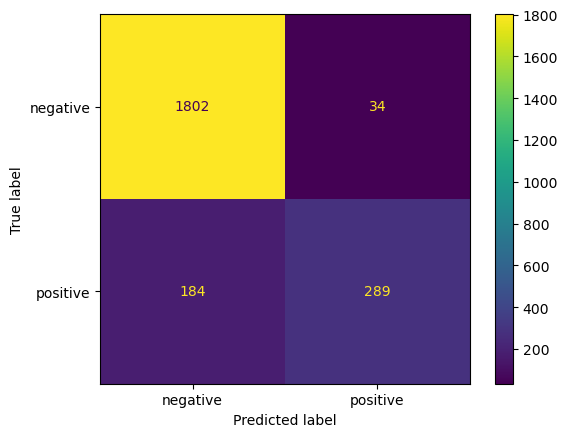

In [52]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

nb_tweets = MultinomialNB()
nb_tweets.fit(x_train_vectorized, y_train)

y_pred_tweets = nb_tweets.predict(x_test_vectorized)

print("Accuracy:",round(accuracy_score(y_test, y_pred_tweets),4))
print("Precision:", round(precision_score(y_test, y_pred_tweets, pos_label="positive"),4))
print("Recall:", round(recall_score(y_test, y_pred_tweets, pos_label="positive"),4))
print("F1-score:", round(f1_score(y_test, y_pred_tweets, pos_label="positive"),4))

cm = confusion_matrix(y_test, y_pred_tweets, labels=["negative", "positive"])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["negative", "positive"]
)
disp.plot()
plt.show()


**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9056 |
| Precision | 0.8947 |
| Recall | 0.611 |
| F1-score | 0.7261 |

**Answer 14:**
_Naive Bayes performed [better/worse] on sentiment than on spam based on the test-set metrics. Its independence assumption is more reasonable for short, formulaic spam messages, where certain words often provide strong clues to the class. Tweets depend more on word order and context; for example, “not good” can express negative sentiment even though “good” is usually positive. Sarcasm and negation make sentiment harder for Naive Bayes because it treats each word as independent._

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---:|---:|
| Accuracy | 0.9839 | 0.9056 |
| Precision | 0.9645 | 0.8947 |
| Recall | 0.9128 | 0.6111 |
| F1-score | 0.9379 | 0.7261 |

In [56]:
# Task 18 — train Logistic Regression on Task A's vectorized features
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(x_train_vectorized, y_train)

lr_predictions = lr_model.predict(x_test_vectorized)

print("Accuracy:", round(accuracy_score(y_test, lr_predictions), 4))
print("Precision:", round(precision_score(y_test, lr_predictions, pos_label="positive"), 4))
print("Recall:", round(recall_score(y_test, lr_predictions, pos_label="positive"), 4))
print("F1-score:", round(f1_score(y_test, lr_predictions, pos_label="positive"), 4))

Accuracy: 0.9199
Precision: 0.8529
Recall: 0.7357
F1-score: 0.79


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | 0.9839 | 0.9199 |
| Precision | 0.9645 | 0.8529 |
| Recall | 0.9128 | 0.7357 |
| F1-score | 0.9379 | **0.7910** |

**Answer 18 (which wins, and does it match expectations):**
_Naive Bayes wins because it has higher accuracy, precision, recall, and F1-score. This is plausible for short, formulaic spam messages, where certain words strongly indicate spam. Logistic Regression does not make Naive Bayes’ word-independence assumption, but that does not guarantee better performance on this dataset._

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
_Naive Bayes performed better on the SMS spam task than on tweet sentiment, with a higher F1-score. Spam messages often contain clear, repeated words such as “claim,” “prize,” and “guaranteed,” which help the model identify spam. I was surprised that some ordinary words, such as “he” and “she,” were among the strongest ham-associated words. On the same SMS features, Naive Bayes outperformed Logistic Regression across all four metrics. This may be because the spam messages contain strong word-level clues that suit Naive Bayes well. However, the independence assumption can miss how words work together—for example, “not good” can express negative sentiment even though “good” alone is usually positive. This limitation may help explain why Naive Bayes had more difficulty with tweets, where context and word combinations matter._

**Answer 20 — Kaggle Notebook Links:**
- Task A: _______
- Task B: _______

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted